# Small Recommendation System Using cosinsimilarity

### Type of filtering
#### content Based filtering
#### collaborative filtering
#### Hybrid Recommendation System
#### Knowladge based Recommandation
#### Demographic-Based Recommendation

### colabarative filtering
#### Recommend items liked by similar users.
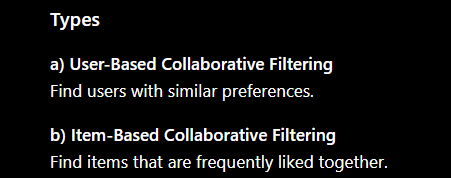
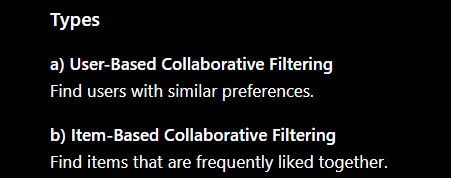

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

In [53]:
rating = {
    'Movie A': [5, 4, 1, 0],
    'Movie B': [4, 5, 5, 0],
    'Movie C': [0, 5, 5, 4],
    'Movie D': [1, 1, 4, 5],
    'Movie E': [5, 4, 0, 1]
}

users = ['john','david','adam','lisa']

In [55]:
df = pd.DataFrame(rating,index=users)

In [57]:
df

,Movie A,Movie B,Movie C,Movie D,Movie E
john,5,4,0,1,5
david,4,5,5,1,4
adam,1,5,5,4,0
lisa,0,0,4,5,1


#### find similar user

In [59]:
from sklearn.metrics.pairwise import cosine_similarity

# find pairwise  similarity -- similarities for john-john, john-lisa,john-adam,...
similarity = cosine_similarity(df)

# covert similariyt to dataframe
similarity_df = pd.DataFrame(similarity,index = df.index,columns=df.index)
similarity_df

,john,david,adam,lisa
john,1.000000,0.818000,0.432836,0.188512
david,0.818000,1.000000,0.777771,0.491173
adam,0.432836,0.777771,1.000000,0.754046
lisa,0.188512,0.491173,0.754046,1.000000


In [61]:
# recommand movie to target user
target_user = 'lisa'

# find user having similar interest as target user
similar_user = similarity_df[target_user].sort_values(ascending=False)
similar_user

lisa     1.000000
adam     0.754046
david    0.491173
john     0.188512
Name: lisa, dtype: float64

In [63]:
# find user most similarity
most_similar_user = similarity_df[target_user].drop(target_user).idxmax()
most_similar_user

'adam'

In [65]:
# recommend movie to user
recommendations = []

for movie in df.columns:
    # search movie which target user not watched yet
    # the most similar user has given > 4
    if df.loc[target_user,movie] == 0 and df.loc[most_similar_user,movie] >= 4:
        recommendations.append(movie)


In [66]:
print(f"Recommanded movie to {target_user} = {recommendations}")

Recommanded movie to lisa = ['Movie B']
